# 모의고사 3회 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display

# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT = next(
    p
    for p in [Path.cwd()] + list(Path.cwd().parents)
    if (p / "기출문제/공통/reconstruction.py").exists()
)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "기출문제/공통"))
from reconstruction import *
from matplotlib import font_manager

font_path = ROOT / "기출문제/공통/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False
HERE = ROOT / "기출문제" / "모의고사/3회"
DATA = HERE / "data"
OUT = HERE / "실행결과"
OUT.mkdir(exist_ok=True)


def load(name):
    return pd.read_csv(DATA / name)


print("데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님")

# 상황형 답안 기록 초기화
_SCENARIO_ROOT = next(
    p
    for p in [Path.cwd()] + list(Path.cwd().parents)
    if (p / "기출문제/공통/scenario_inference.py").is_file()
)
sys.path.insert(0, str(_SCENARIO_ROOT / "기출문제/공통"))
from scenario_inference import (
    reset_reports,
    set_question,
    report_test,
    report_anova,
    report_correlations,
    report_adf,
    report_residuals,
    report_regression_diagnostics,
)

reset_reports(OUT)

데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 매장 매출 설명

**상황을 이해하기**

서로 다른 매장의 판매량과 가격·광고·지역 환경을 비교합니다.

**관측 단위와 판단 목적**

한 행은 독립 매장입니다. Urban은 도심 위치 표시이며 집단 비교와 연속 반응 예측을 구분합니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `Carseats.csv / Urban` | 도심 매장 여부 Yes/No |
| `Carseats.csv / Income` | 지역 소득 지표 |
| `Carseats.csv / Price` | 해당 매장의 가격 지표 |
| `Carseats.csv / Advertising` | 광고 투입 지표 |
| `Carseats.csv / CompPrice` | 경쟁 매장의 가격 지표 |
| `Carseats.csv / Population` | 지역 인구 지표 |
| `Carseats.csv / Age` | 지역 평균 나이 지표 |
| `Carseats.csv / Education` | 교육 수준 지표 |
| `Carseats.csv / Sales` | 매출 지표 |

**고정 분석 조건**

매장 컨설턴트는 Urban(Yes/No)별 Sales와 가격·소득·광고 등의 관계를 살피려 한다. 매장은 독립 표본이며 두 집단의 매출은 정규성을 만족한다고 가정한다. 모분산의 동일성은 주어지지 않았다.


### 1-1

**문제**

도시 매장과 비도시 매장의 평균 매출이 다른지 유의수준 5%에서 판단하시오. 검정 선택 근거·가정·가설·통계량·p-value·기각 여부와 매장 운영 맥락의 결론을 제시하시오.

**풀이 근거와 읽는 순서**

독립 두 집단의 정규 평균 비교이며 모분산 동일성은 알려져 있지 않아 Welch t검정을 선택한다.

H0: μ도시=μ비도시, H1: μ도시≠μ비도시.

분산 검정 결과로 유리한 평균 검정을 사후 선택하지 않는다.

**계산·해석 상세**

두 집단은 독립입니다.

정규성 가정 하 Bartlett을 보고, 등분산 여부와 무관하게 Welch를 사용한 선택 근거를 명시합니다.

귀무가설을 “채택/증명”하지 않습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [2]:
set_question("1-1")
car = load("Carseats.csv")
a = car.loc[car.Urban == "Yes", "Sales"]
b_ = car.loc[car.Urban == "No", "Sales"]
print("Bartlett:", stats.bartlett(a, b_))
print("Welch t-test:", stats.ttest_ind(a, b_, equal_var=False))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_w = stats.ttest_ind(a, b_, equal_var=False)
_va = a.var(ddof=1) / len(a)
_vb = b_.var(ddof=1) / len(b_)
_df = (_va + _vb) ** 2 / (_va**2 / (len(a) - 1) + _vb**2 / (len(b_) - 1))
report_test(
    "Welch 독립 두 표본 t",
    "도시/비도시 평균 매출이 같다",
    "도시/비도시 평균 매출이 다르다",
    _w.statistic,
    _w.pvalue,
    "도시 여부에 따라 평균 매출이 다르다",
    "독립 매장·집단별 정규성 가정·등분산 불필요. 지역의 인과 효과로 단정하지 않음.",
    df=_df,
)

Bartlett: BartlettResult(statistic=np.float64(0.35574228007062925), pvalue=np.float64(0.5508804259216197))
Welch t-test: TtestResult(statistic=np.float64(0.4907940792616884), pvalue=np.float64(0.6239472137614591), df=np.float64(286.94881572070454))
{
  "question": "1-1",
  "method": "Welch 독립 두 표본 t",
  "H0": "도시/비도시 평균 매출이 같다",
  "H1": "도시/비도시 평균 매출이 다르다",
  "statistic": 0.4907940792616884,
  "p_value": 0.6239472137614591,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 매장·집단별 정규성 가정·등분산 불필요. 지역의 인과 효과로 단정하지 않음.",
  "conclusion": "귀무가설을 기각하지 못한다. 도시 여부에 따라 평균 매출이 다르다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "df": 286.94881572070443
}


### 1-2

**문제**

Sales와 CompPrice·Income·Advertising·Population·Price·Age·Education의 선형 관계를 평가하시오. 관계의 방향·크기·가설·p-value·기각 여부를 제시하고 다중 탐색과 비선형성의 한계를 설명하시오.

**풀이 근거와 읽는 순서**

연속 변수의 선형 관계를 Pearson으로 평가한다.

각 H0: rho=0, H1: rho≠0이며 상관 크기와 Holm 보정 p값을 구분한다.

명목 범주 코드에 수치 간격 의미를 부여하지 않는다.

**계산·해석 상세**

전체 상관행렬과 Sales에 대한 개별 r·p값을 보고합니다.

피어슨 상관이 낮다고 비선형 관계까지 없다는 뜻은 아닙니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

    feature         r      p_value
  CompPrice  0.009739 8.666009e-01
     Income  0.570908 2.406563e-27
Advertising  0.409674 1.433849e-13
 Population  0.039799 4.922472e-01
      Price -0.619604 3.366489e-33
        Age  0.003003 9.586883e-01
  Education -0.056047 3.333087e-01


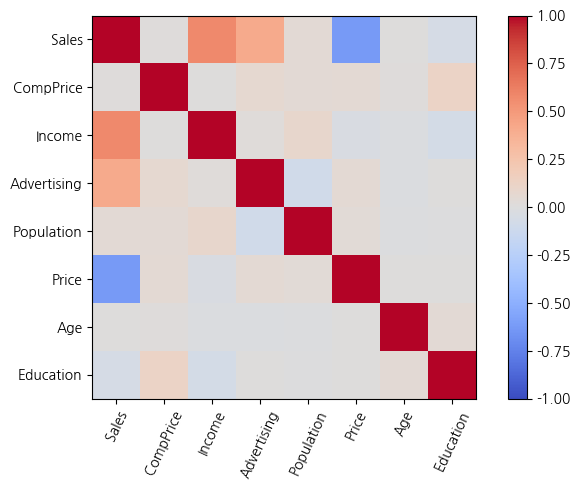

{
  "question": "1-2",
  "method": "Pearson 선형 상관: CompPrice",
  "H0": "rho(Sales,CompPrice)=0",
  "H1": "rho(Sales,CompPrice) != 0",
  "statistic": 0.009738616458626018,
  "p_value": 0.8666009066431151,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각하지 못한다. Sales와 CompPrice 사이에 선형 관계가 있다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "adjusted_p_value": 1.0,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-2",
  "method": "Pearson 선형 상관: Income",
  "H0": "rho(Sales,Income)=0",
  "H1": "rho(Sales,Income) != 0",
  "statistic": 0.57090830874106,
  "p_value": 2.40656310988375e-27,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각한다. Sales와 Income 사이에 선형 관계가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 1.44393786593025e-26,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-2",
  "method": "Pearson 선형 상관: Advertisi

In [3]:
set_question("1-2")
numeric_correlations(
    car,
    "Sales",
    ["CompPrice", "Income", "Advertising", "Population", "Price", "Age", "Education"],
)

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_correlations(
    car,
    "Sales",
    ["CompPrice", "Income", "Advertising", "Population", "Price", "Age", "Education"],
)

### 1-3

**문제**

위 특성을 후보로 매출 설명 모형을 구성하시오. 전체 후보에서 불필요한 변수를 제거하는 선택 기준·과정·최종 회귀식을 제시하고 연관과 인과를 구분하시오.

**풀이 근거와 읽는 순서**

후진제거를 AIC 개선으로 정의합니다.

선택된 계수·절편으로 회귀식을 제시합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [4]:
set_question("1-3")
car_model = select_ols(
    car,
    "Sales",
    ["CompPrice", "Income", "Advertising", "Population", "Price", "Age", "Education"],
    "backward",
)
print("회귀식 계수:", car_model.params.to_dict())

선택 변수: ['Income', 'Advertising', 'Population', 'Price']
   step                                           features         AIC
0     1  Income,Advertising,Population,Price,Age,Education  555.767120
1     2            Income,Advertising,Population,Price,Age  554.488057
2     3                Income,Advertising,Population,Price  553.928824
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.876
Model:                            OLS   Adj. R-squared:                  0.875
Method:                 Least Squares   F-statistic:                     522.5
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          1.69e-132
Time:                        11:26:53   Log-Likelihood:                -271.96
No. Observations:                 300   AIC:                             553.9
Df Residuals:                     295   BIC:                             572.4
Df Model:                   

## 2. 구매 고객 세분화

**상황을 이해하기**

대규모 할인 행사에서 기록한 구매 특성으로 유사한 구매 형태를 탐색합니다.

**관측 단위와 판단 목적**

한 행은 구매 기록입니다. 고객 식별자가 반복될 수 있으므로 군집이 거래 단위인지 고객 집계 단위인지 보고합니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `BlackFriday.csv / User_ID` | 고객 식별자(크기를 거리로 사용하지 않음) |
| `BlackFriday.csv / Product_ID` | 상품 식별자 |
| `BlackFriday.csv / Occupation` | 직업 코드(범주) |
| `BlackFriday.csv / Marital_Status` | 혼인 상태 코드 |
| `BlackFriday.csv / Product_Category_1` | 상품 범주 1 |
| `BlackFriday.csv / Product_Category_2` | 상품 범주 2 |
| `BlackFriday.csv / Product_Category_3` | 상품 범주 3 |
| `BlackFriday.csv / Gender` | 성별 범주 |
| `BlackFriday.csv / Age` | 연령 구간(범주) |
| `BlackFriday.csv / City_Category` | 거주 도시 범주 |
| `BlackFriday.csv / Stay_In_Current_City_Years` | 현 도시 거주 기간 범주 |
| `BlackFriday.csv / Purchase` | 구매금액 지표 |

**고정 분석 조건**

별도 BlackFriday 거래 자료로 유사 구매 특성을 가진 고객을 분류하려 한다. 이 대문항의 전처리·거리 계산·집단 해석은 같은 행과 변수 정의를 공유한다.


### 2-1

**문제**

Product_Category_2/3의 미기재를 0으로 표시하고 세 카테고리 코드 합 Product_all을 만들되 크기의 의미를 검토하시오. ID는 문자열, Occupation·Marital_Status·상품코드는 범주형으로, Gender·Age·City_Category·Stay_In_Current_City_Years는 더미로 구성하시오.

**풀이 근거와 읽는 순서**

범주 코드의 합 Product_all은 문제 지시상 생성하며 거리 특성에서는 제외합니다.

고유 ID도 거리·의미를 갖지 않습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [5]:
set_question("2-1")
black = load("BlackFriday.csv")
black[["Product_Category_2", "Product_Category_3"]] = black[
    ["Product_Category_2", "Product_Category_3"]
].fillna(0)
black["Product_all"] = black[
    ["Product_Category_1", "Product_Category_2", "Product_Category_3"]
].sum(axis=1)
black["User_ID"] = black.User_ID.astype(str)
for c in [
    "Occupation",
    "Marital_Status",
    "Product_Category_1",
    "Product_Category_2",
    "Product_Category_3",
]:
    black[c] = black[c].astype("category")
black1 = pd.concat(
    [
        black,
        pd.get_dummies(
            black[["Gender", "Age", "City_Category", "Stay_In_Current_City_Years"]],
            prefix=["Gender", "Age", "City", "Stay"],
        ),
    ],
    axis=1,
)
print(black1.head())

  User_ID Product_ID Occupation Marital_Status  ... Stay_0 Stay_1 Stay_2 Stay_4+
0      34        P24          9              0  ...  False  False  False    True
1       4         P9          7              1  ...   True  False  False   False
2       7        P22          4              0  ...  False   True  False   False
3      12        P26          9              0  ...   True  False  False   False
4      93        P24          9              0  ...  False  False  False    True

[5 rows x 25 columns]


### 2-2

**문제**

User_ID·Product_ID·원래 Gender/Age/City/Stay 열·Product_all을 거리 입력에서 제외하시오. 남은 값을 수치로 표현·표준화해 k=2~5 집단을 비교하고 집단 수를 선택하시오. 명목 코드 거리의 한계를 설명하시오.

**풀이 근거와 읽는 순서**

범주형의 수치 변환을 요청대로 코드값으로 수행하나 명목 코드 간 거리는 임의입니다.

원핫·혼합거리 대안도 설명합니다.

표준화 후 2~5개 k의 silhouette·inertia를 비교합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

   k  silhouette      inertia
0  2    0.110857  9580.115623
1  3    0.124678  8958.949597
2  4    0.099806  8512.546872
3  5    0.113171  7999.004601


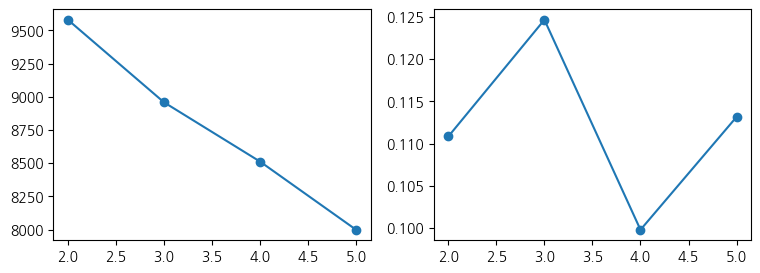

          Purchase  Product_all  clust
clust                                 
0      2533.089700     7.034653    0.0
1      2379.992693     6.835821    1.0
2      2527.265019     6.934010    2.0


In [6]:
set_question("2-2")
exclude = [
    "User_ID",
    "Product_ID",
    "Gender",
    "Age",
    "City_Category",
    "Stay_In_Current_City_Years",
    "Product_all",
]
cluster_X = black1.drop(columns=exclude).copy()
for c in cluster_X.columns:
    cluster_X[c] = cluster_X[c].astype(float)
black_cluster, k_table = cluster(cluster_X, OUT, original=black)

### 2-3

**문제**

선택한 집단 번호를 원자료의 같은 행에 clust로 연결해 CSV를 저장하시오. 집단별 Gender·Age·Purchase 분포로 고객 특성과 활용 방안을 설명하시오.

**풀이 근거와 읽는 순서**

원 입력 행 순서를 유지해 clust를 붙이고 앞 셀에서 CSV를 저장했습니다.

군집 번호는 순위·타깃 라벨이 아닙니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [7]:
set_question("2-3")
print(pd.crosstab(black_cluster.clust, black_cluster.Gender))
print(pd.crosstab(black_cluster.clust, black_cluster.Age))
print(black_cluster.groupby("clust").Purchase.agg(["count", "mean", "median"]))

Gender    F    M
clust           
0        99  103
1       100  101
2       109   88
Age    18-25  26-35  36-45
clust                     
0         65     61     76
1         66     60     75
2         58     68     71
       count         mean       median
clust                                 
0        202  2533.089700  2496.027129
1        201  2379.992693  2416.910387
2        197  2527.265019  2492.250727


## 3. 블로그 반응 요약

**상황을 이해하기**

문서에서 관심 단어의 빈도와 날짜별 관심을 요약합니다.

**관측 단위와 판단 목적**

한 행은 문서 한 건입니다. 품사는 제공된 학습 사전의 표시에 한정됩니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `comments.csv / date` | 문서 작성 날짜 |
| `comments.csv / text` | 분석할 문서 내용 |
| `lexicon.csv / word` | 학습용 품사 사전에 등록된 단어 |
| `lexicon.csv / pos` | Noun=명사, Adjective=형용사 |

**고정 분석 조건**

별도 댓글·날짜·품사 사전으로 블로그 반응을 요약한다. 전체 댓글의 형용사와 2월 댓글의 명사를 구분해 분석하려 한다.


### 3-1

**문제**

숫자·특수문자를 정제하되 문서 ID와 날짜를 보존하시오. 원문·정제 결과의 대응을 확인하시오.

**풀이 근거와 읽는 순서**

숫자·특수 문자 제거 뒤 문서 ID와 날짜를 유지합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [8]:
set_question("3-1")
comments = load("comments.csv")
lexicon = load("lexicon.csv")
comments["clean"] = comments.text.map(clean_text)
print(comments.head())

         date                          text                  clean
0  2026-01-15  호텔 여행 배송 행복 영화 호텔 즐겁다 123 !@  호텔 여행 배송 행복 영화 호텔 즐겁다
1  2026-01-16  배송 공구 배송 영화 영화 호텔 편하다 123 !@  배송 공구 배송 영화 영화 호텔 편하다
2  2026-01-17   가족 공구 맛 여행 공구 여행 편하다 123 !@   가족 공구 맛 여행 공구 여행 편하다
3  2026-01-18  공구 배송 여행 배송 가족 가족 즐겁다 123 !@  공구 배송 여행 배송 가족 가족 즐겁다
4  2026-01-19  학교 공구 여행 배송 여행 배송 빠르다 123 !@  학교 공구 여행 배송 여행 배송 빠르다


### 3-2

**문제**

동봉 사전에 형용사로 등록된 어휘를 추출하고 빈도를 요약하시오. 사전 등재와 단순 빈도 추출을 구분하시오.

**풀이 근거와 읽는 순서**

등록 단어와 POS의 대응을 명시합니다.

단순 토큰을 임의로 형용사라 부르지 않습니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

[['즐겁다'], ['편하다'], ['편하다'], ['즐겁다'], ['빠르다'], ['편하다'], ['즐겁다'], ['즐겁다'], ['즐겁다'], ['좋다']]
  word  count
0  즐겁다     17
1   좋다     15
2  편하다     14
3  빠르다     14


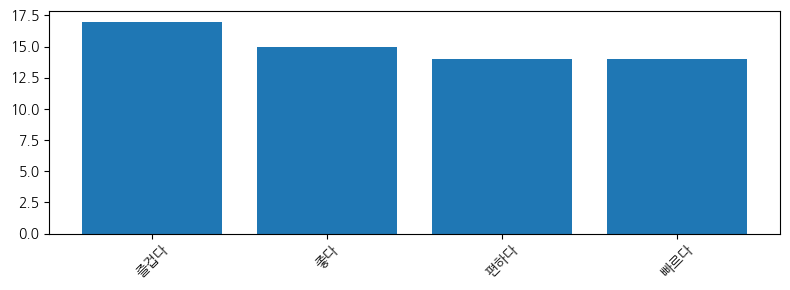

In [9]:
set_question("3-2")
adjectives = lexical_pos(comments.text, lexicon, "Adjective")
print(adjectives[:10])
word_plot(adjectives, 10)

### 3-3

**문제**

날짜를 파싱해 2월 댓글만 선택하고 명사 빈도를 시각화하시오. 전체 댓글 분석과 결과가 달라질 수 있는 이유를 설명하시오.

**풀이 근거와 읽는 순서**

전체 댓글의 단어 빈도가 아니라 2월 댓글을 먼저 필터링합니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

  word  count
0   공구     35
1   학교     22
2   행복     20
3   호텔     17
4   배송     16
5   가족     15
6    맛     15
7   여행     14
8   영화     14


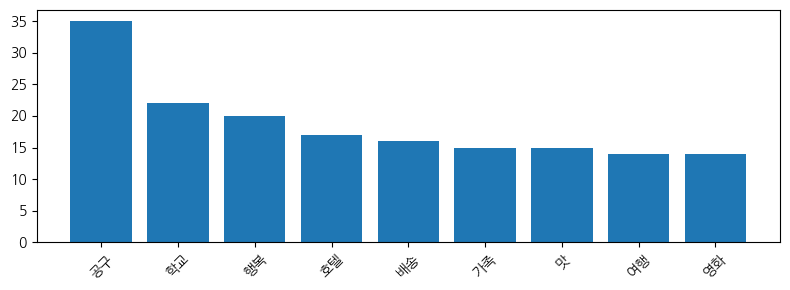

In [10]:
set_question("3-3")
feb = comments[pd.to_datetime(comments.date).dt.month == 2]
assert len(feb) > 0
word_plot(lexical_pos(feb.text, lexicon, "Noun"), 20)